In [1]:
import timeit
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse

from automl import listerDatasets

In [2]:
dataSets = listerDatasets(prefix="data")

In [3]:
from automl import Dataset


def lireDatasetEnginePython(path: Path, n_features: int | None = None) -> Dataset:
    prefix = path.name

    data = path / f"{prefix}.data"
    types = path / f"{prefix}.type"
    solution = path / f"{prefix}.solution"

    types = [line.strip() for line in types.read_text().splitlines() if line.strip()]
    solution = pd.read_csv(solution, header=None, sep=r"\s+", engine="python").to_numpy()

    with data.open() as file:
        premiereLigne = file.readline()

    dataIsSparse = ":" in premiereLigne
    if not dataIsSparse:
        data = pd.read_csv(data, header=None, sep=r"\s+", engine="python").to_numpy()
        return Dataset(path, data, types, solution, dataIsSparse)

    rows: list[int] = []
    columns: list[int] = []
    values: list[float] = []
    nLignes = 0

    with data.open() as file:
        for row, line in enumerate(file):
            nLignes += 1

            for token in line.split():
                column, value = token.split(":", 1)

                rows.append(row)
                columns.append(int(column) - 1)
                values.append(float(value))

    if n_features is None:
        n_features = len(types)

    data = sparse.csr_matrix((values, (rows, columns)), shape=(nLignes, n_features))
    return Dataset(path, data, types, solution, dataIsSparse)

def lireDatasetEngineC(path: Path, n_features: int | None = None) -> Dataset:
    prefix = path.name

    data = path / f"{prefix}.data"
    types = path / f"{prefix}.type"
    solution = path / f"{prefix}.solution"

    types = [line.strip() for line in types.read_text().splitlines() if line.strip()]
    solution = pd.read_csv(solution, header=None, sep=r"\s+", engine="c").to_numpy()

    with data.open() as file:
        premiereLigne = file.readline()

    dataIsSparse = ":" in premiereLigne
    if not dataIsSparse:
        data = pd.read_csv(data, header=None, sep=r"\s+", engine="c").to_numpy()
        return Dataset(path, data, types, solution, dataIsSparse)

    rows: list[int] = []
    columns: list[int] = []
    values: list[float] = []
    nLignes = 0

    with data.open() as file:
        for row, line in enumerate(file):
            nLignes += 1

            for token in line.split():
                column, value = token.split(":", 1)

                rows.append(row)
                columns.append(int(column) - 1)
                values.append(float(value))

    if n_features is None:
        n_features = len(types)

    data = sparse.csr_matrix((values, (rows, columns)), shape=(nLignes, n_features))
    return Dataset(path, data, types, solution, dataIsSparse)

def lireDatasetEngineCInPlace(path: Path, n_features: int | None = None) -> Dataset:
    prefix = path.name

    data = path / f"{prefix}.data"
    types = path / f"{prefix}.type"
    solution = path / f"{prefix}.solution"

    types = [line.strip() for line in types.read_text().splitlines() if line.strip()]
    solution = pd.read_csv(solution, header=None, sep=r"\s+", engine="c").to_numpy()

    with data.open() as file:
        premiereLigne = file.readline()

    dataIsSparse = ":" in premiereLigne
    if not dataIsSparse:
        data = pd.read_csv(data, header=None, sep=r"\s+", engine="c", memory_map=True).to_numpy()
        return Dataset(path, data, types, solution, dataIsSparse)

    rows: list[int] = []
    columns: list[int] = []
    values: list[float] = []
    nLignes = 0

    with data.open() as file:
        for row, line in enumerate(file):
            nLignes += 1

            for token in line.split():
                column, value = token.split(":", 1)

                rows.append(row)
                columns.append(int(column) - 1)
                values.append(float(value))

    if n_features is None:
        n_features = len(types)

    data = sparse.csr_matrix((values, (rows, columns)), shape=(nLignes, n_features))
    return Dataset(path, data, types, solution, dataIsSparse)

def lireDatasetNP(path: Path, n_features: int | None = None) -> Dataset:
    prefix = path.name

    data = path / f"{prefix}.data"
    types = path / f"{prefix}.type"
    solution = path / f"{prefix}.solution"

    types = [line.strip() for line in types.read_text().splitlines() if line.strip()]
    solution = np.loadtxt(solution, dtype=float, ndmin=2)

    with data.open() as file:
        premiereLigne = file.readline()

    dataIsSparse = ":" in premiereLigne
    if not dataIsSparse:
        data = np.loadtxt(data, dtype=float, ndmin=2)
        return Dataset(path, data, types, solution, dataIsSparse)

    rows: list[int] = []
    columns: list[int] = []
    values: list[float] = []
    nLignes = 0

    with data.open() as file:
        for row, line in enumerate(file):
            nLignes += 1

            for token in line.split():
                column, value = token.split(":", 1)

                rows.append(row)
                columns.append(int(column) - 1)
                values.append(float(value))

    if n_features is None:
        n_features = len(types)

    data = sparse.csr_matrix((values, (rows, columns)), shape=(nLignes, n_features))
    return Dataset(path, data, types, solution, dataIsSparse)


In [4]:
def tempsChargementDataSet(dataset_names, repetitions=3, fonction_lecture=None):
    resultats = []

    for name in dataset_names:
        dernier = {}

        def run(name=name):
            dernier["dataset"] = fonction_lecture(path=name)  # noqa: B023

        temps = timeit.repeat(stmt=run, repeat=repetitions, number=1)
        dataset = dernier["dataset"]
        resultats.append(
            {
                "dataset": name,
                "format": "sparse" if dataset.isSparse else "dense",
                "n_samples": dataset.data.shape[0],
                "temps_moyen_s": sum(temps) / len(temps),
                "temps_min_s": min(temps),
                "temps_max_s": max(temps),
            }
        )

    return pd.DataFrame(resultats)

def comparerLectures(fonctions, dataset_names, repetitions=3):
    dfs = []
    for nom, f in fonctions.items():
        df = tempsChargementDataSet(dataset_names, fonction_lecture=f, repetitions=repetitions)
        df["fonction"] = nom
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


In [5]:
from matplotlib import pyplot as plt


def graphiqueComparaison(df, log=True):
    df = df.assign(dataset=df["dataset"].map(lambda p: Path(p).name))
    pivot = df.pivot(index="dataset", columns="fonction", values="temps_moyen_s")
    ax = pivot.plot(kind="bar", figsize=(12, 5))
    ax.set_ylabel("Temps moyen de chargement (s)")
    if log:
        ax.set_yscale("log")
    plt.xticks(rotation=45, ha="right")
    plt.show()


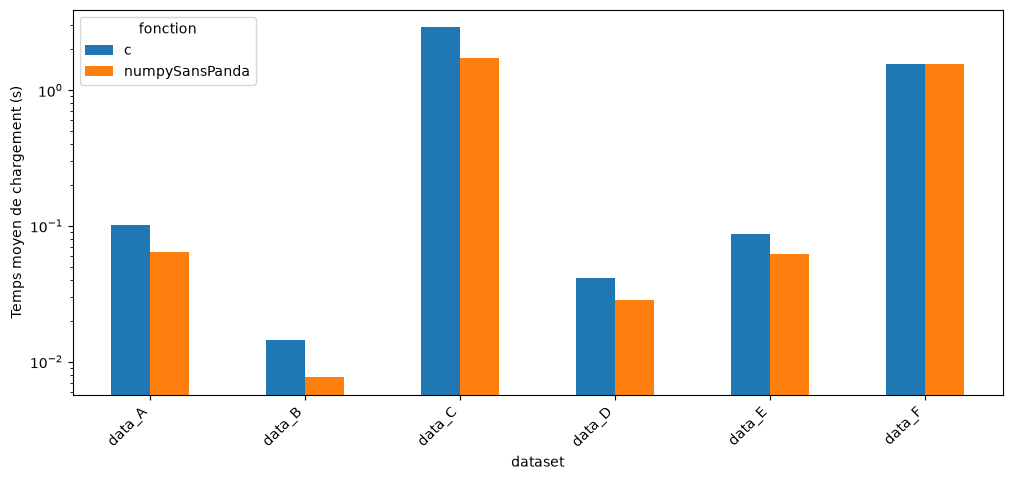

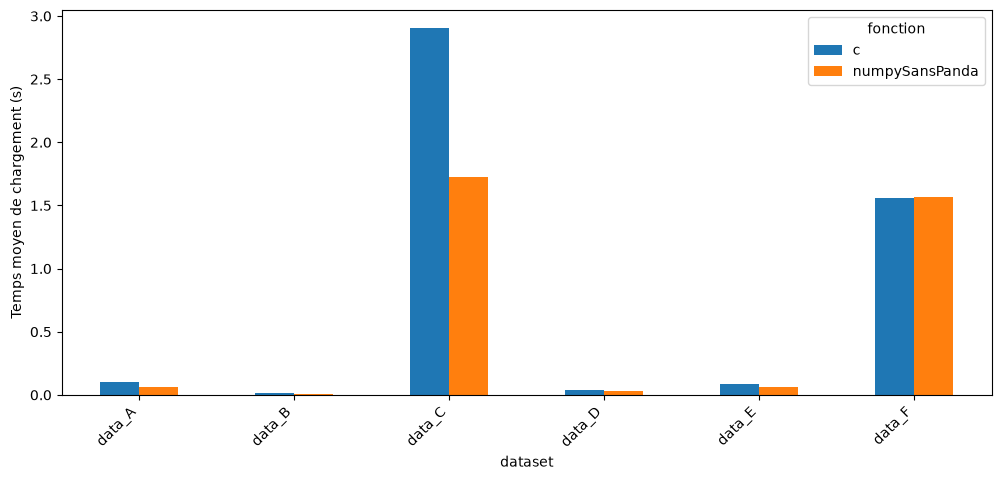

In [ ]:
df = comparerLectures(
    {
        "python": lireDatasetEnginePython,
        "c": lireDatasetEngineC,
        "cInPlace": lireDatasetEngineCInPlace,
        "numpySansPanda": lireDatasetNP,
    },
    listerDatasets(),
)
graphiqueComparaison(df)
graphiqueComparaison(df, log=False)

In [7]:
for p in listerDatasets():
    a, b = lireDatasetEngineC(p), lireDatasetEnginePython(p)

    if a.isSparse:
        assert (a.data != b.data).nnz == 0
    else:
        assert np.allclose(a.data, b.data, equal_nan=True)
    assert np.allclose(a.solution, b.solution, equal_nan=True)